# Differential equations

:::{warning} An experimental feature: be more alert than usual
Differential equations are a new and experimental part of ModelFlow. They are tested on the
examples in this chapter and a few more, far less than the rest of ModelFlow. The syntax, the
names of the generated variables and the defaults may change.

A wrong result here can look entirely plausible, so check more than you would for an ordinary
model:

- **check the step**: halve `DT` and solve again; the results should hardly move;
- **check against an independent solution**, such as SciPy's `solve_ivp` or a closed-form
  solution, on a case where one exists;
- **check what should be conserved** (energy, total population) over the run;
- **read the generated equations** (`print(ode_transform(...))`) and the `report=True` table;
- **check that the solver converged**, in particular with the implicit methods and
  simultaneous auxiliaries, which are the newest part.
:::

Many models outside economics are written in continuous time, as **differential equations**:
the laws of motion of a projectile or a planet, the spread of an epidemic, a chemical reaction.
Each one says how fast a state $S$ changes,

$$
\frac{dS}{dt} = f(S, x)
$$

ModelFlow solves difference equations, one DataFrame row per period. The module `modelode`
connects the two. The modeller writes the derivatives, tags them `<ODE>`, and `ode_transform`
generates the equations of a one-step Runge–Kutta method (Euler, Heun, midpoint, Ralston or
RK4). Each row of the DataFrame is then one time step.

With the explicit methods the generated equations are recursive within a period: every
equation only uses values that are already calculated. ModelFlow orders and evaluates them in
one sweep per time step, with no iteration and no Newton step. Nothing in the solver knows about
differential equations; they are an ordinary ModelFlow model by the time they are solved.

This chapter covers the `<ODE>` tag, what is generated, how the data are laid out, the choice of
method and time step, documented models with lists through `ode_makemodel`, stiff systems with
implicit methods solved by Newton, and the rules a model must follow.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from modelclass import model
from modelode import ode_transform, ode_makemodel, OdeTransformError

## A first model: an epidemic

The SIR model splits a population into the susceptible $S$, the infected $I$ and the recovered
$R$. Susceptibles are infected at a rate proportional to the share of the population that is
infected, and the infected recover at a constant rate:

$$
\frac{dS}{dt} = -\beta \frac{S I}{N}, \qquad
\frac{dI}{dt} = \beta \frac{S I}{N} - \gamma I, \qquad
\frac{dR}{dt} = \gamma I, \qquad N = S + I + R
$$

In ModelFlow each derivative is an equation tagged `<ODE>`: `<ODE> S = f` means
$\frac{dS}{dt} = f$. The other equations are ordinary **auxiliaries**. The parameters are
called `CONTACT` ($\beta$) and `RECOVERY` ($\gamma$): `GAMMA` is the name of a function in
ModelFlow's namespace and can't be used as a variable.

There is no time step and there are no lags in the text. The time step belongs to the
integrator, not to the model.

In [2]:
sir = """
FRML <ODE> S = -INFECTION $
FRML <ODE> I = INFECTION - RECOVERY*I $
FRML <ODE> R = RECOVERY*I $
FRML <>    INFECTION = CONTACT*S*I/N $
FRML <>    N = S + I + R $
FRML <>    SHARE_INFECTED = 100*I/N $
"""

`ode_transform` returns the FRML text of the integrated model. `report=True` shows how each
equation was read:

- a **state** is integrated; the expression is its derivative;
- an **aux** is needed by a derivative and is recalculated at every stage of the step;
- a **report** variable is needed by no derivative; it is calculated once, at the end of the step.

In [3]:
sir_euler = ode_transform(sir, method='euler', report=True)

variable,class,derivative / expression
S,state,-INFECTION
I,state,INFECTION-RECOVERY*I
R,state,RECOVERY*I
INFECTION,aux,CONTACT*S*I/N
N,aux,S + I + R
SHARE_INFECTED,report,100*I/N


## What is generated

With `method='euler'` the generated model is one Euler step: the derivatives are evaluated at
the start of the step (stage 1), and each state moves `DT` times its derivative. The stage
values carry the suffix `__S1`, the derivatives `__K1`.

In [4]:
print(sir_euler)

£ generated by ode_transform, method euler, step DT
£ stage 1
FRML <> S__S1 = S(-1) $
FRML <> I__S1 = I(-1) $
FRML <> R__S1 = R(-1) $
FRML <> N__S1 = S__S1+I__S1+R__S1 $
FRML <> INFECTION__S1 = CONTACT(-1)*S__S1*I__S1/N__S1 $
FRML <> S__K1 = -INFECTION__S1 $
FRML <> I__K1 = INFECTION__S1-RECOVERY(-1)*I__S1 $
FRML <> R__K1 = RECOVERY(-1)*I__S1 $
£ update
FRML <> S = S(-1) + DT*(S__K1) $
FRML <> I = I(-1) + DT*(I__K1) $
FRML <> R = R(-1) + DT*(R__K1) $
£ auxiliaries at the end of the step, and reporting equations
FRML <> INFECTION = CONTACT*S*I/N $
FRML <> N = S+I+R $
FRML <> SHARE_INFECTED = 100*I/N $


A method with more stages evaluates the derivatives at more points within the step and
averages them. Heun's method takes an Euler step as a predictor (stage 2), evaluates the
derivatives again at the predicted point, and uses the average of the two:

In [5]:
print(ode_transform(sir, method='heun'))

£ generated by ode_transform, method heun, step DT
£ stage 1
FRML <> S__S1 = S(-1) $
FRML <> I__S1 = I(-1) $
FRML <> R__S1 = R(-1) $
FRML <> N__S1 = S__S1+I__S1+R__S1 $
FRML <> INFECTION__S1 = CONTACT(-1)*S__S1*I__S1/N__S1 $
FRML <> S__K1 = -INFECTION__S1 $
FRML <> I__K1 = INFECTION__S1-RECOVERY(-1)*I__S1 $
FRML <> R__K1 = RECOVERY(-1)*I__S1 $
£ stage 2
FRML <> S__S2 = S(-1) + DT*(S__K1) $
FRML <> I__S2 = I(-1) + DT*(I__K1) $
FRML <> R__S2 = R(-1) + DT*(R__K1) $
FRML <> N__S2 = S__S2+I__S2+R__S2 $
FRML <> INFECTION__S2 = CONTACT*S__S2*I__S2/N__S2 $
FRML <> S__K2 = -INFECTION__S2 $
FRML <> I__K2 = INFECTION__S2-RECOVERY*I__S2 $
FRML <> R__K2 = RECOVERY*I__S2 $
£ update
FRML <> S = S(-1) + DT*(0.5*S__K1 + 0.5*S__K2) $
FRML <> I = I(-1) + DT*(0.5*I__K1 + 0.5*I__K2) $
FRML <> R = R(-1) + DT*(0.5*R__K1 + 0.5*R__K2) $
£ auxiliaries at the end of the step, and reporting equations
FRML <> INFECTION = CONTACT*S*I/N $
FRML <> N = S+I+R $
FRML <> SHARE_INFECTED = 100*I/N $


For every state `S` and stage `i` there is a stage value `S__S{i}` and a derivative `S__K{i}`;
an auxiliary a derivative needs gets a stage value `A__S{i}`. The update
`S = S(-1) + DT*(b1*S__K1 + b2*S__K2 + ...)` closes the step. The number of equations is

$$
\text{stages} \times (2 \times \text{states} + \text{needed aux}) + \text{states} + \text{aux} + \text{report}
$$

For RK4 and the SIR model: $4 \times (2 \times 3 + 2) + 3 + 2 + 1 = 38$.

In [6]:
msir = model(ode_transform(sir, method='rk4'), modelname='SIR, RK4')
len(msir.endogene)

38

## The data: one row per time step

The DataFrame has one row per time step and an integer index. Row 0 holds the initial state;
the model is solved from row 1. The time step is a column, `DT` by default (`dt=` names
another column). Parameters are ordinary exogenous columns too.

In [7]:
def sir_df(m, dt, days=160, contact=0.3, recovery=0.1):
    n = int(round(days / dt))
    df = pd.DataFrame(0.0, index=range(n + 1), columns=sorted(m.allvar))
    df['DT'] = dt
    df['CONTACT'] = contact
    df['RECOVERY'] = recovery
    df.loc[0, ['S', 'I', 'R']] = 999_000, 1_000, 0
    return df

df = sir_df(msir, dt=0.5)
res = msir(df, 1, df.index[-1], silent=1)
res['DAY'] = res.index * 0.5
res.set_index('DAY')[['S', 'I', 'R', 'SHARE_INFECTED']].iloc[::40].round(1)

,S,I,R,SHARE_INFECTED
DAY,,,,
0.0,999000.0,1000.0,0.0,0.0
20.0,925847.9,48803.8,25348.3,4.9
40.0,287524.7,297326.6,415148.7,29.7
60.0,87154.1,99820.2,813025.7,10.0
80.0,64190.1,20841.2,914968.8,2.1
100.0,60342.6,4085.4,935572.0,0.4
120.0,59620.0,791.9,939588.1,0.1
140.0,59481.0,153.2,940365.8,0.0
160.0,59454.2,29.6,940516.2,0.0


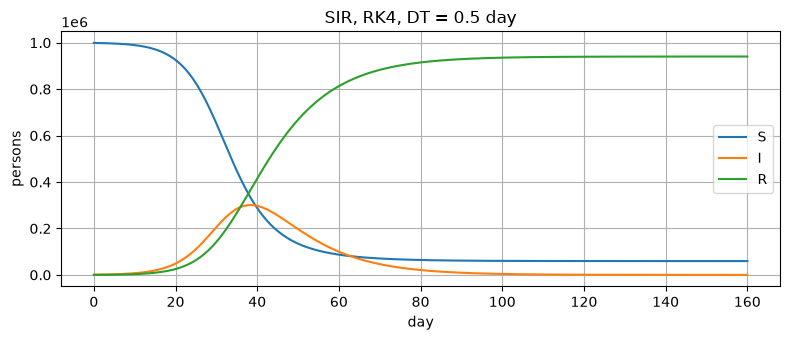

In [8]:
ax = res.set_index('DAY')[['S', 'I', 'R']].plot(figsize=(8, 3.5), grid=True)
ax.set(xlabel='day', ylabel='persons', title='SIR, RK4, DT = 0.5 day');

## The Euler-step form

A state can also be written as the Euler step itself, `S = S(-1) + DT*f`. `ode_transform` reads
the derivative `f` out of the step and treats it as an `<ODE>` equation. Inside `f`, and in the
auxiliaries a derivative needs, `X` and `X(-1)` both mean "X at the current stage": the lag
pattern of the Euler step (explicit or semi-implicit) is discarded.

This is useful for a model that already exists as Euler steps. The integrated model is the same:

In [9]:
sir_steps = """
FRML <> S = S(-1) - DT*INFECTION $
FRML <> I = I(-1) + DT*(INFECTION - RECOVERY*I(-1)) $
FRML <> R = R(-1) + DT*RECOVERY*I $
FRML <> INFECTION = CONTACT*S(-1)*I(-1)/N(-1) $
FRML <> N = S + I + R $
FRML <> SHARE_INFECTED = 100*I/N $
"""
msteps = model(ode_transform(sir_steps, method='rk4'))
res_steps = msteps(df, 1, df.index[-1], silent=1)
(res_steps[['S', 'I', 'R']] - res[['S', 'I', 'R']]).abs().max()

S    0.0
I    0.0
R    0.0
dtype: float64

The `<ODE>` form is still the one to prefer: it states the model and leaves the time step to
the integrator.

## Choosing the method and the time step

`method=` is one of

| `method=` | Order | Stages |
|---|---|---|
| `'euler'` | 1 | 1 |
| `'heun'`, `'midpoint'`, `'ralston'` | 2 | 2 |
| `'rk4'` (default) | 4 | 4 |

The order says how the error falls with the time step: halving `DT` divides the error by
about $2^{\text{order}}$, 2 for Euler and 16 for RK4. To check a step, compare with a
high-accuracy reference. Here it is SciPy's `solve_ivp` with tolerance $10^{-12}$:

In [10]:
def sir_rhs(t, y, contact=0.3, recovery=0.1):
    s, i, r = y
    infection = contact * s * i / (s + i + r)
    return [-infection, infection - recovery * i, recovery * i]

ref = solve_ivp(sir_rhs, (0, 160), [999_000, 1_000, 0], method='DOP853',
                rtol=1e-12, atol=1e-12, dense_output=True)

models = {method: model(ode_transform(sir, method=method)) for method in ['euler', 'heun', 'rk4']}
steps = [2, 1, 0.5, 0.25]
errors = {}
for method, m in models.items():
    for dt in steps:
        d = sir_df(m, dt)
        r = m(d, 1, d.index[-1], silent=1)
        exact_i = ref.sol(r.index.to_numpy() * dt)[1]
        errors[method, dt] = np.abs(r['I'].to_numpy() - exact_i).max()

errors = pd.Series(errors).unstack(0)
errors.index.name = 'DT (days)'
errors.map('{:.1e}'.format)

,euler,heun,rk4
DT (days),,,
0.25,1.1e+04,1.8e+02,2.0e-02
0.50,2.3e+04,6.9e+02,3.1e-01
1.00,4.4e+04,2.6e+03,4.5e+00
2.00,8.4e+04,9.1e+03,6.2e+01


The largest error in the number of infected over the 160 days. Each halving of the step divides
the error by about 2, 4 and 16. The estimated order is the slope of the error against the step
in logs:

In [11]:
np.polyfit(np.log(steps), np.log(errors), 1)[0].round(2)

array([-0.97, -1.89, -3.87])

With RK4 a step of half a day is already accurate to a fraction of a person. A model that does
not settle should be checked the same way: halve `DT` and compare.

A method that is not in the list is given as its Butcher tableau, a dict with `a` (strictly
lower triangular: explicit methods only), `b` and `c`. The built-in tables are in
`modelode.BUTCHER`:

```python
from fractions import Fraction
kutta3 = dict(a=[[], [0.5], [-1, 2]], b=[Fraction(1, 6), Fraction(2, 3), Fraction(1, 6)], c=[0, 0.5, 1])
text = ode_transform(sir, method=kutta3)
```

## Exogenous variables that change over time

Exogenous columns may change from row to row. Each stage reads an exogenous variable at its own
time: the stage at the start of the step reads `E(-1)`, the stage at the end reads `E`, a stage
in between interpolates. That is visible in the Heun equations above, where stage 1 uses
`CONTACT(-1)` and stage 2 `CONTACT`.

A scenario is then an ordinary ModelFlow scenario: change a column and solve again. Here contacts
are halved from day 25:

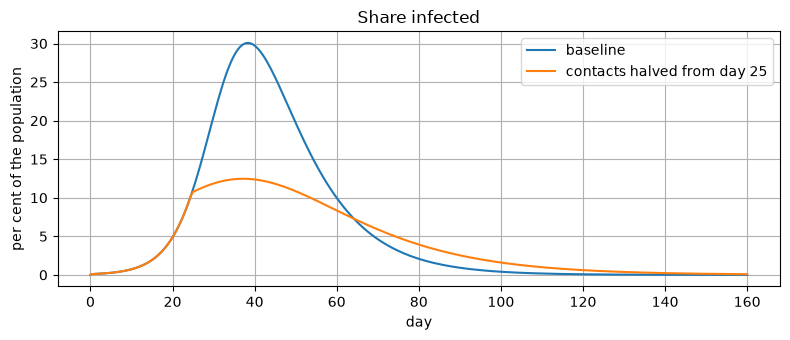

In [12]:
dt = 0.5
base = sir_df(msir, dt)
lockdown = base.copy()
lockdown.loc[int(25 / dt):, 'CONTACT'] = 0.15

compare = pd.DataFrame({
    'baseline': msir(base, 1, base.index[-1], silent=1)['SHARE_INFECTED'],
    'contacts halved from day 25': msir(lockdown, 1, lockdown.index[-1], silent=1)['SHARE_INFECTED']})
compare.index = compare.index * dt
ax = compare.plot(figsize=(8, 3.5), grid=True)
ax.set(xlabel='day', ylabel='per cent of the population', title='Share infected');

`DT` can change over the rows as well, for instance a smaller step around an event where the
states change fast.

An instantaneous event, such as a vaccination campaign that moves people from $S$ to $R$ in one
day, is a jump in a state, not a derivative. Solve up to the row, change the states in that
row, and solve on from the next row.

## A documented model with lists: `ode_makemodel`

`ode_transform` reads FRML text. To write the model as a Markdown document, with `list`,
`doable` and `sum` as in the [Model specification](model%20specification.ipynb) chapter, use
`ode_makemodel`. It runs `Makemodel` on the text, then `ode_transform` on Makemodel's expanded
equations, and returns the model and the `Makemodel` instance.

The example is the SIR model in three regions. The infected in the other regions infect too,
with a weight `MIX`. **`NO{list}`** means *all the other elements*: in an equation that loops over
`regions`, `NO{regions}` is the list of the other regions, and `i__{NO{regions}}` runs over their
infected.

In [13]:
regional = r"""
**SIR in three regions.**

Each region $r$ has its own susceptible, infected and recovered. The infected in the other
regions $q \ne r$ count with the weight $mix$:

$$
\frac{dS_r}{dt} = -\beta \, S_r \, \frac{I_r + mix \sum_{q \ne r} I_q}{N_r}
$$

>list regions = regions : NORTH SOUTH WEST

>doable <ODE> s__{regions} = -infection__{regions}
>doable <ODE> i__{regions} = infection__{regions} - recovery*i__{regions}
>doable <ODE> r__{regions} = recovery*i__{regions}
>doable infection__{regions} = contact*s__{regions}*(i__{regions} + mix*sum(NO{regions}, i__{NO{regions}}))/n__{regions}
>doable n__{regions} = s__{regions} + i__{regions} + r__{regions}
"""
mregions, mm = ode_makemodel(regional, method='rk4', report=True)

variable,class,derivative / expression
S__NORTH,state,-INFECTION__NORTH
S__SOUTH,state,-INFECTION__SOUTH
S__WEST,state,-INFECTION__WEST
I__NORTH,state,INFECTION__NORTH-RECOVERY*I__NORTH
I__SOUTH,state,INFECTION__SOUTH-RECOVERY*I__SOUTH
I__WEST,state,INFECTION__WEST-RECOVERY*I__WEST
R__NORTH,state,RECOVERY*I__NORTH
R__SOUTH,state,RECOVERY*I__SOUTH
R__WEST,state,RECOVERY*I__WEST
INFECTION__NORTH,aux,CONTACT*S__NORTH*(I__NORTH + MIX*( I__SOUTH+ I__WEST))/N__NORTH


`mm.render` shows the model as written. The lists that `NO{regions}` needs are generated, and
shown in place of the list line:

In [14]:
mm.render

**SIR in three regions.**

Each region $r$ has its own susceptible, infected and recovered. The infected in the other
regions $q \ne r$ count with the weight $mix$:

<IPython.core.display.Math object>

```text
>list regions = regions : NORTH   SOUTH   WEST   /
>               NO      : NONORTH NOSOUTH NOWEST
>list NONORTH = NONORTH : SOUTH WEST
>list NOSOUTH = NOSOUTH : NORTH WEST
>list NOWEST  = NOWEST  : NORTH SOUTH
```

*Generated from the list above:* the sublist `NO` gives each element of `regions` the name of the list of all the other elements, e.g. `NONORTH` = SOUTH WEST. In an equation that loops over `regions`, `NO{regions}` is that list and `{NO{regions}}` runs over its elements.


```text
>doable <ODE> s__{regions} = -infection__{regions}
>doable <ODE> i__{regions} = infection__{regions} - recovery*i__{regions}
>doable <ODE> r__{regions} = recovery*i__{regions}
>doable infection__{regions} = contact*s__{regions}*(i__{regions} + mix*sum(NO{regions}, i__{NO{regions}}))/n__{regions}
>doable n__{regions} = s__{regions} + i__{regions} + r__{regions}
```

The expanded equations, before Runge–Kutta, are in `mm.expanded_frml`. The epidemic starts in
the north. The west is smaller, so the infected in the other regions weigh more there:

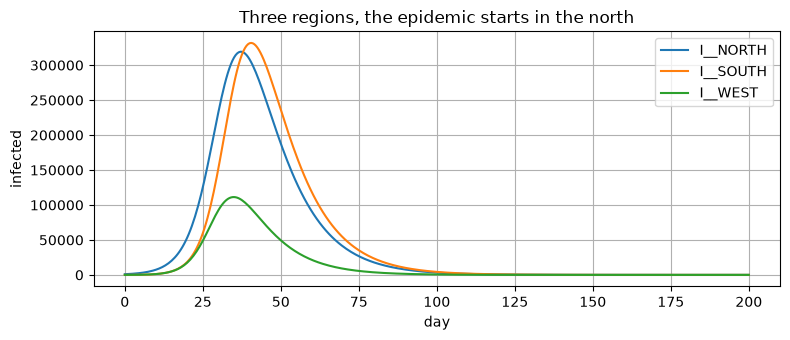

In [15]:
dt = 0.5
n = int(round(200 / dt))
d = pd.DataFrame(0.0, index=range(n + 1), columns=sorted(mregions.allvar))
d['DT'], d['CONTACT'], d['RECOVERY'], d['MIX'] = dt, 0.3, 0.1, 0.05
d.loc[0, ['S__NORTH', 'I__NORTH']] = 999_000, 1_000
d.loc[0, 'S__SOUTH'] = 1_000_000
d.loc[0, 'S__WEST'] = 300_000

r = mregions(d, 1, d.index[-1], silent=1)
r.index = r.index * dt
ax = r[['I__NORTH', 'I__SOUTH', 'I__WEST']].plot(figsize=(8, 3.5), grid=True)
ax.set(xlabel='day', ylabel='infected', title='Three regions, the epidemic starts in the north');

The same machinery gives the N-body problem: `modelode.nbody_template(bodies, dims)` is Newton's
law of gravitation as a documented Markdown model, with `NO{bodies}` for the pull of all the
other bodies, and `nbody_makemodel` builds it. A dimension list (`list dims = dims : X Y Z`)
writes the coordinate equations once. Here are three equal masses on the figure-eight orbit, where all three follow the same curve:

relative energy drift over the period: 3.0e-14


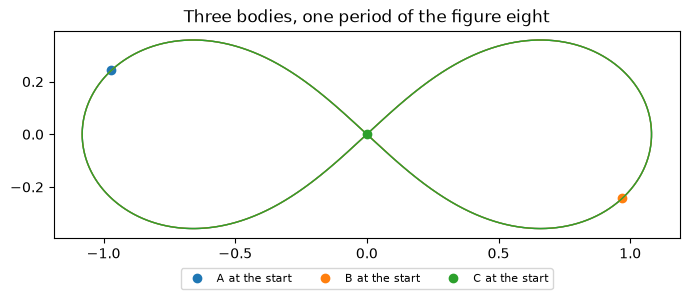

In [16]:
from modelode import nbody_makemodel, make_df, energy

bodies = ['A', 'B', 'C']
mbody, mm_body = nbody_makemodel(bodies, dims=2, method='rk4')

masses = {b: 1.0 for b in bodies}
pos0 = {'A': (-0.97000436, 0.24308753), 'B': (0.97000436, -0.24308753), 'C': (0.0, 0.0)}
vc = (-0.93240737, -0.86473146)
vel0 = {'A': (-vc[0] / 2, -vc[1] / 2), 'B': (-vc[0] / 2, -vc[1] / 2), 'C': vc}

d = make_df(mbody, bodies, masses, pos0, vel0, g=1.0, dt=0.001, t_max=6.3259)
orbit = mbody(d, 1, d.index[-1], silent=1)

fig, ax = plt.subplots(figsize=(7, 4))
for b in bodies:
    line, = ax.plot(orbit[f'POS__{b}__X'], orbit[f'POS__{b}__Y'], lw=1)
    ax.plot(*pos0[b], 'o', color=line.get_color(), label=f'{b} at the start')
ax.set(aspect='equal', title='Three bodies, one period of the figure eight')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncols=3, fontsize=8);

e = energy(orbit, bodies, masses, g=1.0)
print(f'relative energy drift over the period: {abs(e.iloc[-1] / e.iloc[0] - 1):.1e}')

## Stiff systems: implicit methods and Newton

:::{note} The newest and least tested part
Everything in this section creates a simultaneous block in every time step. Check the results
against an independent solution before you rely on them.
:::

A system is **stiff** when it combines a fast and a slow process. Here $Y$ is pulled towards a
slowly moving target $1/(1+t)$ at the rate $K = 1000$:

$$
\frac{dY}{dt} = -K \left(Y - \frac{1}{1+t}\right)
$$

After a short adjustment, $Y$ just follows the target. Even so, an explicit method needs a step
below about $2/K$ to stay stable, however smooth the solution is. With `DT = 0.01`, Euler and RK4
blow up:

In [17]:
stiff = """
FRML <ODE> Y = -K*(Y - 1/(1+T)) $
FRML <ODE> T = 1 $
"""

def stiff_df(m, dt=0.01, k=1000.0, t_max=1.0):
    n = int(round(t_max / dt))
    df = pd.DataFrame(0.0, index=range(n + 1), columns=sorted(m.allvar))
    df['DT'], df['K'] = dt, k
    df.loc[0, 'Y'] = 2.0
    return df

ref_stiff = solve_ivp(lambda t, y: [-1000.0 * (y[0] - 1 / (1 + t))], (0, 1), [2.0],
                      method='Radau', rtol=1e-12, atol=1e-12)
y_ref = ref_stiff.y[0, -1]

for method in ['euler', 'rk4']:
    m = model(ode_transform(stiff, method=method))
    d = stiff_df(m)
    print(f'{method:6} Y(1) = {m(d, 1, d.index[-1], silent=1).loc[d.index[-1], "Y"]:.3e}   '
          f'(reference {y_ref:.6f})')

euler  Y(1) = 2.654e+95   (reference 0.500250)
rk4    Y(1) = 2.448e+246   (reference 0.500250)


An **implicit** method evaluates the derivative at the point it is solving for. Backward Euler,
the simplest, is

$$
Y_t = Y_{t-1} + \Delta t \, f(Y_t)
$$

$Y_t$ is on both sides, so every time step is a small simultaneous system. ModelFlow solves
simultaneous systems anyway, so an implicit method is just another Butcher tableau, with
nonzeros on or above the diagonal of `a`:

| `method=` | Order |
|---|---|
| `'backward_euler'` | 1 |
| `'trapezoid'` (Crank–Nicolson), `'implicit_midpoint'` | 2 |
| `'radau3'` (Radau IIA, two stages) | 3 |

`ode_transform` says when the result is simultaneous. Here is the generated backward Euler
step, where `Y__S1` and `Y__K1` determine each other:

In [18]:
print(ode_transform(stiff, method='backward_euler'))

ode_transform: the method backward_euler is implicit, so every time step holds a simultaneous block. Solve it with solver='newton_ng', with a tight relconv (e.g. 1e-12) so the solver's tolerance stays below the error of the method. Gauss-Seidel (the default) diverges on stiff systems, and the legacy solver='newton' stops at an absolute change of 0.001 (newton_absconv).
£ generated by ode_transform, method backward_euler, step DT
£ stage 1
FRML <> Y__S1 = Y(-1) + DT*(Y__K1) $
FRML <> T__S1 = T(-1) + DT*(T__K1) $
FRML <> Y__K1 = -K*(Y__S1-1/(1+T__S1)) $
FRML <> T__K1 = 1 $
£ update
FRML <> Y = Y(-1) + DT*(Y__K1) $
FRML <> T = T(-1) + DT*(T__K1) $
£ auxiliaries at the end of the step, and reporting equations


**Which solver.** Each period now has to be solved by iteration, and the choice of solver
matters:

- the default for a simultaneous model is **Gauss-Seidel**, which diverges when `DT` times the
  stiffness exceeds 1 (here $0.01 \times 1000 = 10$);
- the legacy `solver='newton'` stops when the change is below 0.001 in absolute terms
  (`newton_absconv`), which is far above the error of the method;
- **`solver='newton_ng'`** with a tight `relconv` is the one to use. Its default tolerance
  leaves errors of order $10^{-9}$, which matter when the method itself is accurate.

In [19]:
import contextlib, io

rows = {}
for method in ['backward_euler', 'trapezoid', 'implicit_midpoint', 'radau3']:
    with contextlib.redirect_stdout(io.StringIO()):     # the note from ode_transform, shown above
        m = model(ode_transform(stiff, method=method))
    d = stiff_df(m)
    last = d.index[-1]
    with np.errstate(all='ignore'), contextlib.redirect_stdout(io.StringIO()):   # a 'not converged' line per period
        gauss = m(d, 1, last, silent=1).loc[last, 'Y']
    newton = m(d, 1, last, silent=1, solver='newton_ng', relconv=1e-12).loc[last, 'Y']
    rows[method] = {'Gauss-Seidel (default)': f'{gauss:.3g}',
                    "newton_ng": f'{newton:.10f}',
                    'error, newton_ng': f'{abs(newton - y_ref):.1e}'}
pd.DataFrame(rows).T

,Gauss-Seidel (default),newton_ng,"error, newton_ng"
backward_euler,nan,0.5002515105,1.3e-06
trapezoid,nan,0.5002502472,3.1e-09
implicit_midpoint,nan,0.5002471176,3.1e-06
radau3,nan,0.5002502478,2.6e-09


With Newton all four are stable at a step five times the explicit limit of $2/K = 0.002$. The
trapezoid rule and Radau are accurate to about $3 \times 10^{-9}$. Backward Euler is first order,
and the implicit midpoint rule, although second order, damps the fast adjustment at the start
only weakly; both are off by a few times $10^{-6}$. For a stiff system the order of a method is
not the whole story.

**Simultaneous auxiliaries.** The same goes for auxiliaries that determine each other, an
algebraic loop inside the derivative, such as a price and a quantity set together. Each stage
then holds a small simultaneous block, also with an explicit method:

In [20]:
loop = """
FRML <ODE> X = -P*X $
FRML <> P = 0.5 + 0.1*Q $
FRML <> Q = X + 0.2*P $
"""
mloop = model(ode_transform(loop, method='rk4'))
d = pd.DataFrame(0.0, index=range(501), columns=sorted(mloop.allvar))
d['DT'] = 0.01
d.loc[0, 'X'] = 1.0
x5 = mloop(d, 1, 500, silent=1, solver='newton_ng', relconv=1e-12).loc[500, 'X']

# P = (0.5 + 0.1*X)/0.98 once the loop is solved by hand
ref_loop = solve_ivp(lambda t, x: [-(0.5 + 0.1 * x[0]) / 0.98 * x[0]], (0, 5), [1.0],
                     method='DOP853', rtol=1e-12, atol=1e-12)
print(f'X(5) = {x5:.10f}, reference {ref_loop.y[0, -1]:.10f}')

ode_transform: auxiliaries needed by a derivative are simultaneous: Q -> P, so every time step holds a simultaneous block. Solve it with solver='newton_ng', with a tight relconv (e.g. 1e-12) so the solver's tolerance stays below the error of the method. Gauss-Seidel (the default) diverges on stiff systems, and the legacy solver='newton' stops at an absolute change of 0.001 (newton_absconv).
The feedback variables are not directly connected, so the feedback order is left as found


X(5) = 0.0658578675, reference 0.0658578675


Implicit methods cost more per step: a Newton solve instead of a sweep. They pay off only when
the system is stiff. For a system that isn't stiff, an explicit method with a smaller step is
simpler and safer.

## The rules

- **No time step and no lags inside a derivative.** Inside `f`, and in the auxiliaries a
  derivative needs, `X` and `X(-1)` both mean X at the current stage. A lag of 2 or more, a lead
  or a [fixed period](fixed%20periods.ipynb) is an error: one-step methods have no delays.
- **`DT` is a column**, named with `dt=`. It may change over the rows. It must not appear inside
  an `<ODE>` equation or an auxiliary, only in an Euler step `S = S(-1) + DT*f`.
- **Auxiliaries a derivative needs** are recalculated at every stage. If they are
  simultaneous among themselves, solve with `solver='newton_ng'`, as above.
- **An auxiliary that refers to itself** (`T = T(-1) + 1`) is an error: make it a state,
  `<ODE> T = 1`.
- **Each variable is determined once**, and names ending in `__S1`, `__K1`, ... are reserved for
  the generated equations.

All problems are listed before `OdeTransformError` is raised:

In [21]:
try:
    ode_transform("""
    FRML <ODE> X = -A*X(-2) $
    FRML <>    Y = Y(-1) + 1 $
    """)
except OdeTransformError as err:
    print('OdeTransformError:', err)

ode_transform: the model is not an ODE system that can be transformed:
 * auxiliary Y refers to itself; with lags collapsed it is simultaneous. If it is a state write it as Y = Y(-1) + DT*f or tag it <ODE>:
   FRML <> Y = Y(-1) + 1 $
 * lag/lead X(-2) is not allowed (only X and X(-1); no delays):
   FRML <ODE> X = -A*X(-2) $
OdeTransformError: 2 problem(s), see above


## Quick reference

```python
from modelode import ode_transform, ode_makemodel

text = ode_transform(frml_text, method='rk4', dt='DT', report=True)  # FRML text
m = model(text)

m, mm = ode_makemodel(markdown_text, method='rk4')                    # Markdown with list/doable
m, mm = ode_makemodel(text, method='heun', type_input='modelflow')    # a plain string
mm.render, mm.expanded_frml                                           # the source as written / expanded
```

| Written | Meaning |
|---|---|
| `FRML <ODE> S = f $` | $\frac{dS}{dt} = f$ |
| `FRML <> S = S(-1) + DT*f $` | the same, as an Euler step |
| `FRML <> A = g $` | an auxiliary: recalculated at every stage if a derivative needs it |
| `NO{list}` | all the other elements of `list` (in `doable`, `DO` and `sum`) |
| `method=` | explicit `'euler'`, `'heun'`, `'midpoint'`, `'ralston'`, `'rk4'`; implicit `'backward_euler'`, `'trapezoid'`, `'implicit_midpoint'`, `'radau3'`; or a Butcher tableau dict |

The data: one row per time step, row 0 holds the initial state, solve from row 1, `DT` a column.
An implicit method or simultaneous auxiliaries: `m(df, 1, n, solver='newton_ng', relconv=1e-12)`.